### importing libraries



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### loading the dataset


In [3]:
data = pd.read_csv(r"../Data/kenya_mobile_money_transactions.csv",parse_dates=["transaction_timestamp"])

In [4]:
data.head()

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status
0,TXN0000142,2024-01-01 07:51:33,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62.0,41335.52,Completed
1,TXN0002262,2024-01-01 07:54:30,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0.0,181880.31,Completed
2,TXN0004820,2024-01-01 08:07:24,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33.0,73354.11,Completed
3,TXN0003825,2024-01-01 08:35:18,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62.0,9511.86,Completed
4,TXN0003076,2024-01-01 09:02:16,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100.0,222644.38,Completed


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   transaction_id         6000 non-null   str           
 1   transaction_timestamp  6000 non-null   datetime64[us]
 2   customer_id            6000 non-null   str           
 3   customer_name          6000 non-null   str           
 4   gender                 6000 non-null   str           
 5   age                    6000 non-null   int64         
 6   county                 6000 non-null   str           
 7   phone_number           6000 non-null   int64         
 8   channel                6000 non-null   str           
 9   transaction_type       6000 non-null   str           
 10  merchant_category      2449 non-null   str           
 11  device_type            6000 non-null   str           
 12  amount_kes             6000 non-null   float64       
 13  transaction_fe

**checking for missing values**

In [6]:
data.isnull().sum()

transaction_id              0
transaction_timestamp       0
customer_id                 0
customer_name               0
gender                      0
age                         0
county                      0
phone_number                0
channel                     0
transaction_type            0
merchant_category        3551
device_type                 0
amount_kes                  0
transaction_fee_kes         0
balance_after_kes           0
status                      0
dtype: int64

### exploratory data analysis


1.Compute total fee revenue (transaction_fee_kes) per calendar month, then add a column showing the month-over-month % change. Which month grew fastest? (Skills: time bucketing, LAG() / .pct_change().)

In [7]:
completed = data[data["status"]=="Completed"]

In [8]:
## monthly revenue trend
monthly_revenue = (completed.set_index("transaction_timestamp").resample("ME")["transaction_fee_kes"].sum().reset_index())

print(monthly_revenue)

   transaction_timestamp  transaction_fee_kes
0             2024-01-31              33876.0
1             2024-02-29              31452.0
2             2024-03-31              33417.0
3             2024-04-30              33705.0
4             2024-05-31              37474.0
5             2024-06-30              31925.0
6             2024-07-31              33923.0
7             2024-08-31              32716.0
8             2024-09-30              32513.0
9             2024-10-31              34355.0
10            2024-11-30              33452.0
11            2024-12-31              33501.0


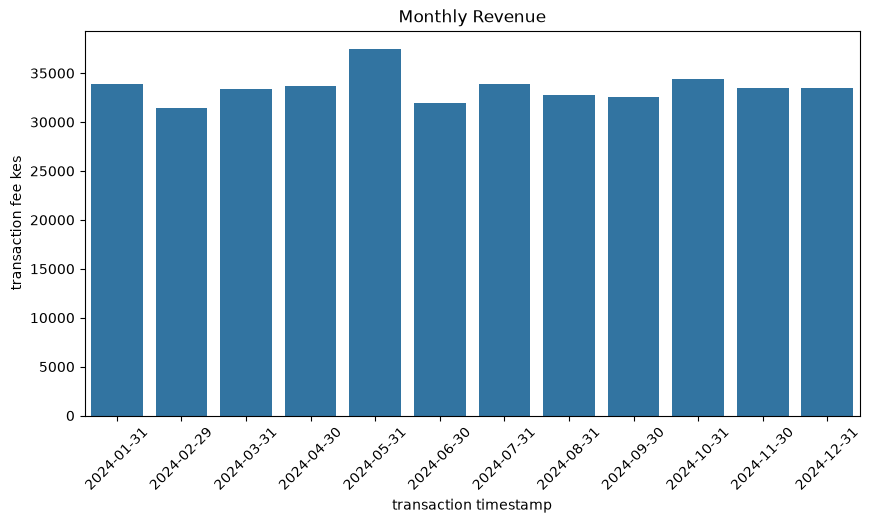

In [9]:
## visualising monthly revenue overtime
plt.figure(figsize=(10, 5))

sns.barplot(data=monthly_revenue, x="transaction_timestamp", y="transaction_fee_kes")
plt.title("Monthly Revenue")
plt.xlabel("transaction timestamp")
plt.ylabel("transaction fee kes")
plt.xticks(rotation=45)
plt.show()

In [10]:
## month over month percentage change
monthly_revenue["MOM_growth_%"] = (monthly_revenue["transaction_fee_kes"].pct_change() * 100)
monthly_revenue

,transaction_timestamp,transaction_fee_kes,MOM_growth_%
0,2024-01-31,33876.0,NaN
1,2024-02-29,31452.0,-7.155508
2,2024-03-31,33417.0,6.247615
3,2024-04-30,33705.0,0.861837
4,2024-05-31,37474.0,11.182317
5,2024-06-30,31925.0,-14.807600
6,2024-07-31,33923.0,6.258418
7,2024-08-31,32716.0,-3.558058
8,2024-09-30,32513.0,-0.620492
9,2024-10-31,34355.0,5.665426


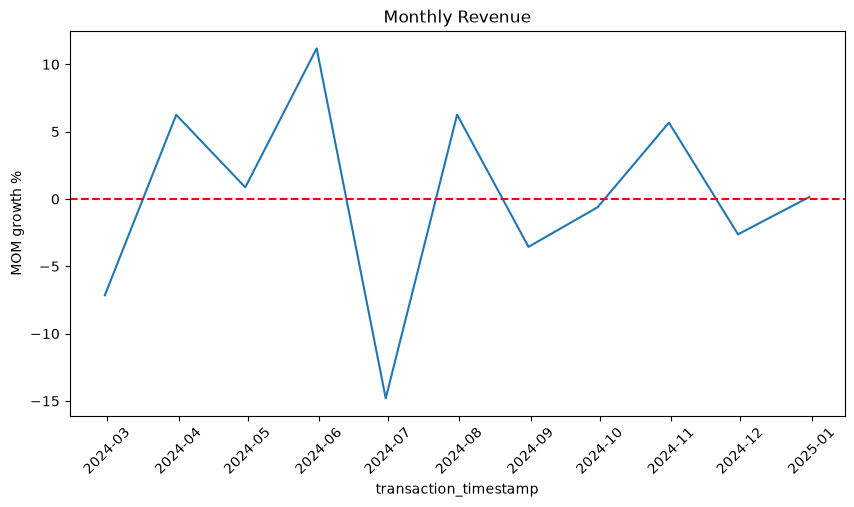

In [11]:
plt.figure(figsize=(10, 5))

sns.lineplot(monthly_revenue, x="transaction_timestamp", y="MOM_growth_%")
plt.axhline(y=0, color="red", linestyle="--")
plt.title("Monthly Revenue")
plt.xlabel("transaction_timestamp")
plt.ylabel("MOM growth %")
plt.xticks(rotation=45)
plt.show()

**conclusion**
- The month with the highest month over month percentage change was june 2024.
- july 2024 had the highest negative month over month percentage  change.

** 2.Build a day-of-week × hour-of-day matrix of transaction counts. Identify the single busiest hour block. (Skills: extracting hour & weekday from a timestamp, pivoting.)**

In [14]:
completed["weekday"] = data["transaction_timestamp"].dt.day_name()
completed["hour"] = data["transaction_timestamp"].dt.hour

In [15]:
completed.head()

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status,weekday,hour
0,TXN0000142,2024-01-01 07:51:33,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62.0,41335.52,Completed,Monday,7
1,TXN0002262,2024-01-01 07:54:30,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0.0,181880.31,Completed,Monday,7
2,TXN0004820,2024-01-01 08:07:24,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33.0,73354.11,Completed,Monday,8
3,TXN0003825,2024-01-01 08:35:18,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62.0,9511.86,Completed,Monday,8
4,TXN0003076,2024-01-01 09:02:16,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100.0,222644.38,Completed,Monday,9


__Pivot Table__

In [18]:
pivot_table = completed.pivot_table(
    index="hour", 
    columns="weekday",
    values="transaction_id",
    aggfunc="count",
    fill_value=0
)

pivot_table

weekday,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
hour,,,,,,,
0,11,10,9,7,17,13,10
1,8,9,10,6,12,11,10
2,7,8,10,9,11,16,11
3,10,17,13,4,17,15,11
4,18,11,12,5,13,10,7
5,7,10,12,11,14,4,8
6,27,38,33,21,39,43,28
7,33,36,37,40,40,43,56
8,45,38,48,40,44,51,40


In [20]:
peak = (completed.groupby(["weekday","hour"]).size().reset_index()).sort_values(name="transaction", ascending=False)
peak

TypeError: DataFrame.sort_values() got an unexpected keyword argument 'name'

__conclusion__
The highest number of transaction were conducted on wednesday at 9am.

3. For each county, rank customers by total amount transacted and return the top 3 per county. (Skills: RANK() / ROW_NUMBER() partitioned by county, or groupby().rank().)

__information needed__
- county
- customer name
- customer id
- amount transacted
- Number of transaction per customer

In [25]:
customer_totals =completed.groupby(["county", "customer_id", "customer_name"])["amount_kes"].sum().reset_index()

customer_totals


,county,customer_id,customer_name,amount_kes
0,Bomet,CUST00018,Njoroge Waweru,295383.78
1,Bomet,CUST00107,Wairimu Omollo,172953.56
2,Bomet,CUST00123,Kiprop Gichuru,229925.30
3,Bomet,CUST00164,Adhiambo Wabwire,113764.81
4,Bomet,CUST00182,Kibet Wekesa,26367.93
...,...,...,...,...
794,Uasin Gishu,CUST00695,Rotich Kimani,123042.27
795,Uasin Gishu,CUST00734,Rotich Kiplagat,392892.88
796,Uasin Gishu,CUST00750,Ochieng Njoroge,195589.16
797,Uasin Gishu,CUST00763,Mwangi Otieno,416877.20


In [27]:
customer_totals["rank"] = customer_totals.groupby("county")["amount_kes"].rank(ascending=False)

top_three = customer_totals[customer_totals["rank"]<=3]

top_three.sort_values(by=["county","rank"])

,county,customer_id,customer_name,amount_kes,rank
10,Bomet,CUST00465,Mutua Musyoka,330868.23,1.0
15,Bomet,CUST00709,Kagwe Kamau,310710.67,2.0
5,Bomet,CUST00185,Wairimu Otieno,309514.15,3.0
30,Bungoma,CUST00229,Rotich Gichuru,472761.38,1.0
35,Bungoma,CUST00331,Nafula Langat,391095.20,2.0
41,Bungoma,CUST00570,Maina Chepkwony,374698.69,3.0
61,Garissa,CUST00573,Kagwe Chepkwony,366407.86,1.0
57,Garissa,CUST00388,Njoroge Kiplagat,282178.41,2.0
58,Garissa,CUST00398,Kariuki Gichuru,270122.27,3.0
82,Homa Bay,CUST00685,Njoroge Musyoka,471429.90,1.0


In [24]:
completed.columns

Index(['transaction_id', 'transaction_timestamp', 'customer_id',
       'customer_name', 'gender', 'age', 'county', 'phone_number', 'channel',
       'transaction_type', 'merchant_category', 'device_type', 'amount_kes',
       'transaction_fee_kes', 'balance_after_kes', 'status', 'weekday',
       'hour'],
      dtype='str')

4.Create a daily transaction-count series, then compute the 7-day rolling average of daily volume. On how many days did volume exceed 1.5× its rolling average? (Skills: resampling to daily, rolling windows.)

__Information needed__
- Transaction_id
- weekday
- Transaction_timestamp
- day

In [29]:
daily = completed.set_index("transaction_timestamp").resample("D")["transaction_id"].count()

daily

transaction_timestamp
2024-01-01    18
2024-01-02    17
2024-01-03    22
2024-01-04    13
2024-01-05    11
              ..
2024-12-27    14
2024-12-28    19
2024-12-29    15
2024-12-30    15
2024-12-31    14
Freq: D, Name: transaction_id, Length: 366, dtype: int64

In [32]:
rolling = daily.rolling(7).mean()

results = pd.DataFrame({
    "daily": daily,
    "rolling_average" : rolling
})

results["above_1.5_times"] = results["daily"]>1.5*results["rolling_average"]

results

,daily,rolling_average,above_1.5_times
transaction_timestamp,,,
2024-01-01,18,NaN,False
2024-01-02,17,NaN,False
2024-01-03,22,NaN,False
2024-01-04,13,NaN,False
2024-01-05,11,NaN,False
...,...,...,...
2024-12-27,14,13.714286,False
2024-12-28,19,15.142857,False
2024-12-29,15,14.714286,False


In [ ]:
results["above_1.5_times"].sum()